# 2.2-B. EDA específico de series de tiempo

El problema es de series de tiempo (DECISIONES.md): un modelo global pronostica, con horizonte de
una semana, `y_reg = log1p(tasa_t1 / base8)` de cada corredor (mercado + municipio de origen) a
partir de la historia del propio corredor y de covariables. Este cuaderno cubre los cinco ítems
del bloque B del enunciado y termina con las implicaciones para el diseño. Cada análisis cierra
con tres puntos: decisión de preprocesamiento, impacto en la arquitectura y riesgo de fuga.

**Datos usados.** Solo el entrenamiento: semanas objetivo hasta el 2024-10-21. La prueba de 2025
no se lee en este cuaderno. Las cifras que se citan en el texto se guardan en
`eda/resultados/series_*.json`.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import signal

sys.path.insert(0, str(Path.cwd()))
import comun as C  # noqa: E402

warnings.filterwarnings("ignore")
C.estilo()
pd.set_option("display.width", 140, "display.precision", 4)

p = C.cargar()
tr = p[p["particion"] == "entrenamiento"].copy()
del p  # el resto del cuaderno solo ve el entrenamiento
print(f"filas de entrenamiento: {len(tr):,} | corredores: {tr.groupby(C.CLAVE).ngroups:,} | "
      f"semanas objetivo: {tr['semana_t1'].min().date()} a {tr['semana_t1'].max().date()} "
      f"({tr['semana_t1'].nunique()})")

# Serie de cada corredor con lo que el panel deja conocer (semana t de cada fila y semana t+1)
T, corredores, semanas = C.matriz_tasa(tr, hasta=C.FIN_TRAIN)
print(f"matriz corredor x semana: {T.shape[0]:,} x {T.shape[1]} | celdas con dato: {np.mean(~np.isnan(T)):.3f}")
R = {}

filas de entrenamiento: 622,244 | corredores: 4,305 | semanas objetivo: 2018-01-29 a 2024-10-21 (352)
matriz corredor x semana: 4,305 x 353 | celdas con dato: 0.424


## B.1 Visualización y descomposición

Con 4.305 series no se puede mirar cada una, así que se trabaja en dos niveles: la serie nacional
(media semanal de `y_reg` en todas las filas) y seis corredores con al menos 300 semanas en
riesgo, elegidos al azar con la semilla 42. La descomposición STL (periodo 52, versión robusta) se
aplica a la serie nacional. Los quiebres en la media se buscan por segmentación binaria con
penalización BIC, con segmentos de al menos 26 semanas.

semanas objetivo sin ninguna fila: 0
fuerza de la estacionalidad 0.435 | fuerza de la tendencia 0.043
quiebres en la media de la serie nacional: []
media de y_reg por segmento: [0.611]


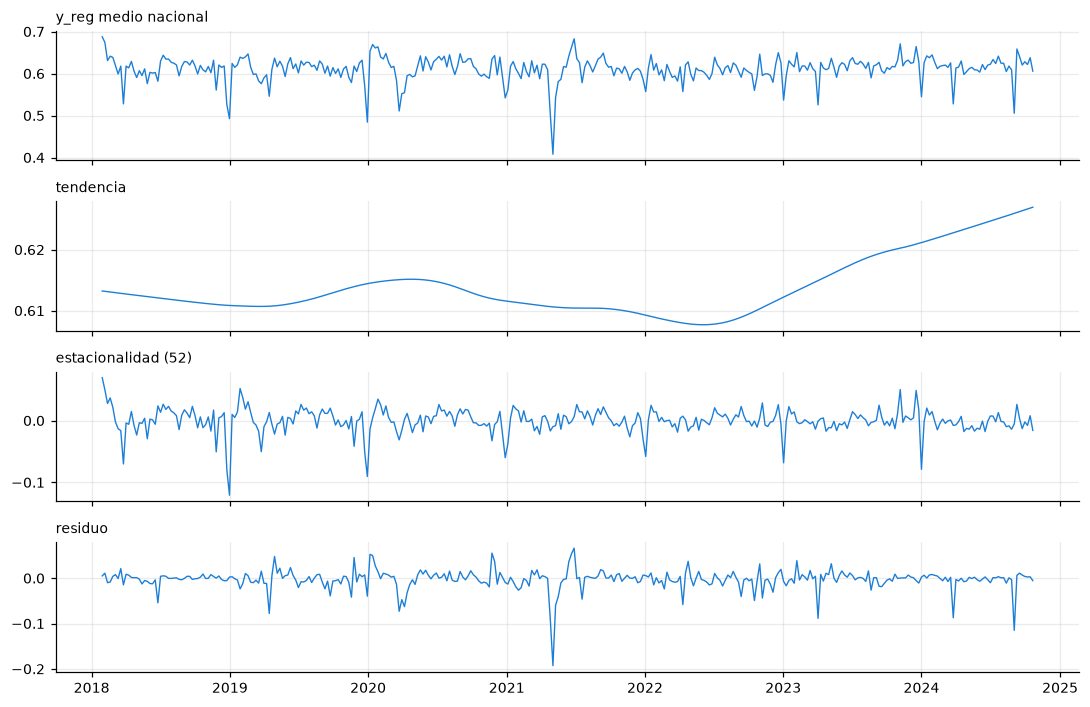

In [2]:
from statsmodels.tsa.seasonal import STL

nac = tr.groupby("semana_t1")[C.OBJ].mean()
nac = nac.reindex(pd.date_range(nac.index.min(), nac.index.max(), freq="W-MON"))
print("semanas objetivo sin ninguna fila:", int(nac.isna().sum()))
nac = nac.interpolate()  # solo para STL y el periodograma de la serie agregada
stl = STL(nac, period=52, robust=True).fit()
f_est = max(0.0, 1 - np.var(stl.resid) / np.var(stl.seasonal + stl.resid))
f_ten = max(0.0, 1 - np.var(stl.resid) / np.var(stl.trend + stl.resid))
cortes = C.segmentacion_binaria(nac.to_numpy(), min_tam=26)
fechas_corte = [str(nac.index[c].date()) for c in cortes]
medias_seg = [float(s.mean()) for s in np.split(nac.to_numpy(), cortes)]
print(f"fuerza de la estacionalidad {f_est:.3f} | fuerza de la tendencia {f_ten:.3f}")
print("quiebres en la media de la serie nacional:", fechas_corte)
print("media de y_reg por segmento:", np.round(medias_seg, 3))
R["descomposicion"] = {"fuerza_estacionalidad": f_est, "fuerza_tendencia": f_ten,
                       "quiebres": fechas_corte, "medias_segmentos": medias_seg,
                       "semanas_sin_filas": int(tr.groupby("semana_t1").size().reindex(nac.index).isna().sum())}

fig, ax = plt.subplots(4, 1, figsize=(10, 6.5), sharex=True)
for a_, serie, tit in zip(ax, [nac, stl.trend, stl.seasonal, stl.resid],
                          ["y_reg medio nacional", "tendencia", "estacionalidad (52)", "residuo"]):
    a_.plot(serie.index, serie.to_numpy(), color=C.AZUL, lw=0.9)
    a_.set_title(tit, loc="left", fontsize=9)
for c in cortes:
    ax[0].axvline(nac.index[c], color=C.ROJO, ls=":", lw=1)
plt.tight_layout()
C.figura(fig, "series_stl_nacional")
plt.show()

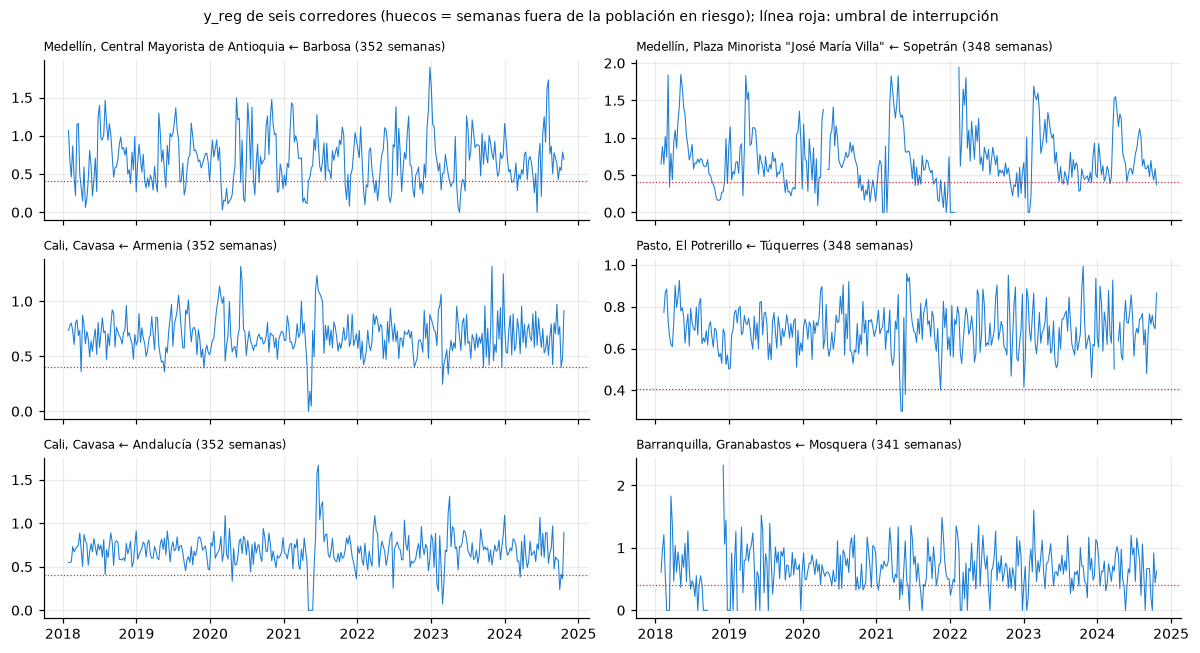

In [3]:
filas_c = tr.groupby(C.CLAVE).size()
rng = np.random.default_rng(C.SEMILLA)
ejemplo = filas_c[filas_c >= 300].index.to_numpy()
ejemplo = ejemplo[rng.choice(len(ejemplo), 6, replace=False)]
fig, ax = plt.subplots(3, 2, figsize=(11, 6), sharex=True)
for a_, (m, mp) in zip(ax.ravel(), ejemplo):
    g = tr[(tr["mercado"] == m) & (tr["cod_mpio"] == mp)].set_index("semana_t1")
    serie = g[C.OBJ].reindex(semanas + pd.Timedelta(days=7))
    a_.plot(serie.index, serie.to_numpy(), color=C.AZUL, lw=0.7)
    a_.axhline(np.log(1.5), color=C.ROJO, ls=":", lw=0.8)
    a_.set_title(f"{m} ← {g['mpio_origen'].iloc[0].title()} ({len(g)} semanas)", loc="left", fontsize=8)
fig.suptitle("y_reg de seis corredores (huecos = semanas fuera de la población en riesgo); línea roja: umbral de interrupción",
             fontsize=9)
plt.tight_layout()
C.figura(fig, "series_corredores_ejemplo")
plt.show()

La segmentación binaria no encuentra quiebres en la media de la serie nacional: ningún corte
supera la penalización BIC, y la media de `y_reg` se mantiene en 0,611 durante todo el
entrenamiento. La STL asigna una fuerza de 0,435 a la estacionalidad anual y de 0,043 a la
tendencia. Es lo esperable, porque `y_reg` ya divide cada semana por la base de 8 semanas de su
corredor, lo que elimina el nivel y casi toda la tendencia.

Los seis corredores muestran lo que el agregado esconde: semanas con `y_reg` = 0 (el corredor no
envió nada en t+1), picos aislados muy por encima de la base y tramos vacíos cuando el corredor sale
de la población en riesgo. Esos tramos son el problema central de faltantes, que se trata en B.5.

* **Preprocesamiento.** No se diferencia ni se quita tendencia, porque la normalización por `base8`
  ya cumple esa función. La posición en el año (`sem_sin`, `sem_cos`) se mantiene como covariable.
* **Arquitectura.** Para que el ciclo anual cuente, la ventana debe llegar al rezago 52 o el modelo
  debe recibir la estacionalidad como covariable.
* **Fuga.** La STL se ajusta con toda la serie de entrenamiento, así que cada componente usa semanas
  futuras. Solo sirve para describir: ninguna componente de la STL entra como variable al modelo.

## B.2 Estacionariedad: ADF y KPSS conjuntas

ADF (H0: raíz unitaria, rezagos por AIC) y KPSS (H0: estacionariedad alrededor de una media,
rezagos automáticos) se aplican a la serie nacional y a 300 corredores escogidos al azar entre los
que tienen al menos 150 semanas con `y_reg` en el entrenamiento. En cada corredor se usan sus
semanas en riesgo consecutivas en el orden del tiempo. La lectura conjunta separa cuatro
escenarios.

In [4]:
from statsmodels.tsa.stattools import adfuller, kpss


def adf_kpss(x):
    # KPSS avisa cuando el estadístico queda fuera de su tabla: el p real es mayor que 0,10
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return adfuller(x, autolag="AIC")[1], kpss(x, regression="c", nlags="auto")[1]


pa_n, pk_n = adf_kpss(nac.to_numpy())
print(f"serie nacional: p ADF = {pa_n:.2e} | p KPSS = {pk_n:.3f} → {C.escenario_adf_kpss(pa_n, pk_n)}")
largos = filas_c[filas_c >= 150].index.to_numpy()
muestra = largos[rng.choice(len(largos), 300, replace=False)]
grupos = tr.sort_values("semana_t1").groupby(C.CLAVE)[C.OBJ]
esc = []
for clave in muestra:
    x = grupos.get_group(tuple(clave)).to_numpy()
    if x.std() > 0:
        esc.append(C.escenario_adf_kpss(*adf_kpss(x)))
esc = pd.Series(esc).value_counts(normalize=True)
print(f"corredores con >= 150 semanas en riesgo: {len(largos):,}; muestra evaluada: 300")
print(esc.round(3).to_string())
R["estacionariedad"] = {"nacional": {"p_adf": pa_n, "p_kpss": pk_n, "escenario": C.escenario_adf_kpss(pa_n, pk_n)},
                        "corredores_elegibles": int(len(largos)), "muestra": 300,
                        "escenarios_corredores": esc.to_dict()}

serie nacional: p ADF = 7.74e-06 | p KPSS = 0.100 → estacionaria (coinciden)


corredores con >= 150 semanas en riesgo: 1,726; muestra evaluada: 300
estacionaria (coinciden)       0.947
conflicto: ambas rechazan      0.050
no estacionaria (coinciden)    0.003


La serie nacional es estacionaria según ambas pruebas: ADF rechaza la raíz unitaria
(p = 7,7 × 10⁻⁶) y KPSS no rechaza la estacionariedad (p ≥ 0,10; el estadístico queda fuera de la
tabla de statsmodels, así que el p real es mayor). En los 300 corredores con al menos 150 semanas
en riesgo, el 94,7 % es estacionario según ambas pruebas, el 5,0 % cae en el conflicto en que ambas
rechazan (lo típico de un quiebre de nivel o de una estacionalidad no modelada) y el 0,3 % no es
estacionario según ambas. En la escala de `y_reg`, la no estacionariedad es la excepción.

* **Preprocesamiento.** Se modela `y_reg` sin diferenciar. La escala de cada ventana sale de la base
  de 8 semanas de la propia fila, que solo usa el pasado.
* **Arquitectura.** Como casi todas las series son estacionarias en esta escala, un modelo global
  puede compartir parámetros entre corredores sin un tratamiento por serie.
* **Fuga.** Ninguna: las pruebas solo describen el entrenamiento y no fijan ningún parámetro del
  modelo.

## B.3 Dependencia temporal y longitud de la ventana

**ACF y PACF.** En la serie nacional se calculan con bandas del 95 %. En los corredores se usa una
ACF agrupada sobre la matriz corredor × semana: la serie de cada corredor es
`log(1 + tasa / media del corredor)` centrada por corredor, y la autocorrelación en el rezago k
promedia todos los pares de semanas observadas a distancia k. La PACF agrupada se obtiene de esa
ACF con la recursión de Durbin–Levinson. El periodograma de la serie nacional busca periodicidades.

**Rezagos útiles para pronosticar.** La ACF mide dependencia lineal en la serie, pero la pregunta
de diseño es cuánta historia mejora el pronóstico de `y_reg`. Para responderla, se ajusta una
regresión ridge (α = 1) que usa como entradas las últimas L semanas de cada corredor, normalizadas
por la base de 8 semanas de la fila, y una máscara de dato presente. Se ajusta con 200.000 filas
tomadas al azar entre las semanas objetivo hasta 60 semanas antes del final del entrenamiento, y se
evalúa con el MAE de las últimas 52 semanas (un hueco de 8 semanas separa ambos bloques). Es una
validación interna del entrenamiento y no reemplaza la validación de origen móvil de los modelos.

ACF nacional (rezagos 1, 2, 4, 13, 26, 52): [ 0.366  0.094  0.034  0.018 -0.014  0.249] | banda ± 0.104
PACF nacional (rezagos 1-6): [ 0.367 -0.047  0.041  0.005 -0.043 -0.032]
ACF agrupada de los corredores: {1: 0.307, 2: 0.289, 3: 0.235, 4: 0.231, 8: 0.14, 13: 0.106, 26: 0.075, 39: 0.053, 52: 0.091, 53: 0.084, 78: -0.009, 104: 0.016} | banda ±0.0024
PACF agrupada (rezagos 1-8, 13, 26, 52): [0.307 0.216 0.115 0.106 0.039 0.053 0.015 0.028 0.01  0.01  0.018]
periodos dominantes del periodograma nacional (semanas): [25.1 17.6 13.5  5.8]


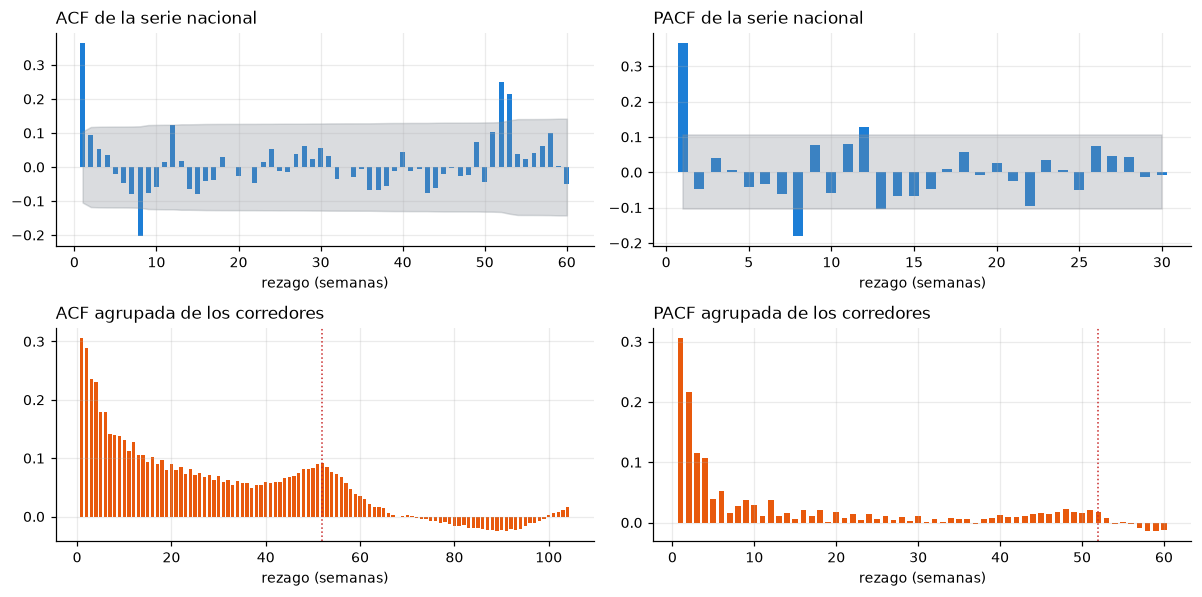

In [5]:
from statsmodels.tsa.stattools import acf, pacf

a_n, ci_n = acf(nac, nlags=60, alpha=0.05, fft=True)
pa_nv, cip_n = pacf(nac, nlags=30, alpha=0.05)
Zr = np.log1p(T / np.nanmean(T, axis=1, keepdims=True))
Zr = Zr - np.nanmean(Zr, axis=1, keepdims=True)
acf_c = C.acf_agrupada(Zr, 104)


def durbin_levinson(r, k_max):
    """PACF a partir de una ACF (r[0] = 1)."""
    phi = np.zeros((k_max + 1, k_max + 1))
    out = [1.0]
    phi[1, 1] = r[1]
    out.append(r[1])
    for k in range(2, k_max + 1):
        num = r[k] - np.sum(phi[k - 1, 1:k] * r[1:k][::-1])
        den = 1 - np.sum(phi[k - 1, 1:k] * r[1:k])
        phi[k, k] = num / den
        phi[k, 1:k] = phi[k - 1, 1:k] - phi[k, k] * phi[k - 1, 1:k][::-1]
        out.append(phi[k, k])
    return np.array(out)


pacf_c = durbin_levinson(acf_c, 60)
fr, Pxx = signal.periodogram(nac.to_numpy() - nac.mean())
top = np.argsort(Pxx)[::-1][:4]
n_pares = int((~np.isnan(Zr)).sum())
banda_c = 1.96 / np.sqrt(n_pares)
rez = [1, 2, 3, 4, 8, 13, 26, 39, 52, 53, 78, 104]
print("ACF nacional (rezagos 1, 2, 4, 13, 26, 52):", np.round(a_n[[1, 2, 4, 13, 26, 52]], 3),
      "| banda ±", round(1.96 / np.sqrt(len(nac)), 3))
print("PACF nacional (rezagos 1-6):", np.round(pa_nv[1:7], 3))
print("ACF agrupada de los corredores:", {k: round(float(acf_c[k]), 3) for k in rez}, f"| banda ±{banda_c:.4f}")
print("PACF agrupada (rezagos 1-8, 13, 26, 52):", np.round(pacf_c[[1, 2, 3, 4, 5, 6, 7, 8, 13, 26, 52]], 3))
print("periodos dominantes del periodograma nacional (semanas):", np.round(1 / fr[top], 1))
R["dependencia"] = {"acf_nacional": a_n.tolist(), "pacf_nacional": pa_nv.tolist(), "acf_corredores": acf_c.tolist(),
                    "pacf_corredores": pacf_c.tolist(), "banda_corredores": banda_c,
                    "periodos_dominantes": (1 / fr[top]).tolist()}

fig, ax = plt.subplots(2, 2, figsize=(11, 5.5))
k = np.arange(len(a_n))
ax[0, 0].bar(k[1:], a_n[1:], color=C.AZUL, width=0.6)
ax[0, 0].fill_between(k[1:], ci_n[1:, 0] - a_n[1:], ci_n[1:, 1] - a_n[1:], color=C.GRIS, alpha=0.3)
ax[0, 0].set_title("ACF de la serie nacional", loc="left")
ax[0, 1].bar(np.arange(1, len(pa_nv)), pa_nv[1:], color=C.AZUL, width=0.6)
ax[0, 1].fill_between(np.arange(1, len(pa_nv)), cip_n[1:, 0] - pa_nv[1:], cip_n[1:, 1] - pa_nv[1:], color=C.GRIS, alpha=0.3)
ax[0, 1].set_title("PACF de la serie nacional", loc="left")
ax[1, 0].bar(np.arange(1, 105), acf_c[1:], color=C.NARANJA, width=0.7)
ax[1, 0].axvline(52, color=C.ROJO, ls=":", lw=1)
ax[1, 0].set_title("ACF agrupada de los corredores", loc="left")
ax[1, 1].bar(np.arange(1, 61), pacf_c[1:], color=C.NARANJA, width=0.7)
ax[1, 1].axvline(52, color=C.ROJO, ls=":", lw=1)
ax[1, 1].set_title("PACF agrupada de los corredores", loc="left")
for a_ in ax.ravel():
    a_.set_xlabel("rezago (semanas)")
plt.tight_layout()
C.figura(fig, "series_acf_pacf")
plt.show()

filas de ajuste: 508,775 (muestra de 200.000) | filas evaluadas: 98,874
  L  mae_eval  frac_semanas_con_dato  mejora_vs_L_anterior
  1    0.3059                 1.0000                   NaN
  2    0.3011                 0.9872                0.0048
  4    0.2980                 0.9680                0.0032
  8    0.2959                 0.9391                0.0021
 13    0.2946                 0.9160                0.0013
 26    0.2933                 0.8858                0.0014
 39    0.2926                 0.8686                0.0007
 52    0.2916                 0.8565                0.0010
 78    0.2915                 0.8336                0.0001
104    0.2912                 0.8166                0.0003
referencias en el mismo bloque: {'persistencia': 0.3457, 'mediana_del_ajuste': 0.3103, 'sin_cambio_log2': 0.3134}


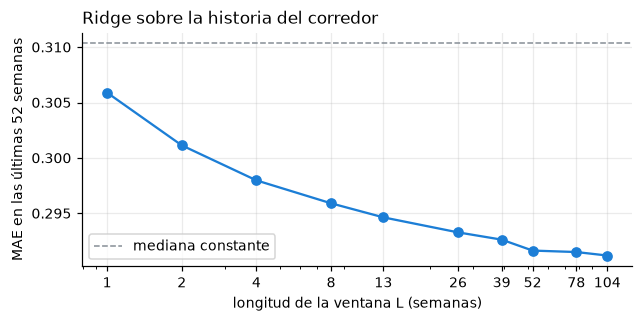

In [6]:
from sklearn.linear_model import Ridge

c_idx = corredores.get_indexer(pd.MultiIndex.from_frame(tr[C.CLAVE]))
s_idx = semanas.get_indexer(tr["semana"])
y = tr[C.OBJ].to_numpy()
base = tr["base8"].to_numpy()
ultima = tr["semana_t1"].max()
ajuste = (tr["semana_t1"] <= ultima - pd.Timedelta(weeks=52 + C.HUECO)).to_numpy()
evalua = (tr["semana_t1"] > ultima - pd.Timedelta(weeks=52)).to_numpy()
sub = rng.choice(np.flatnonzero(ajuste), 200_000, replace=False)


def ventana(L):
    cols = s_idx[:, None] + np.arange(-L + 1, 1)[None, :]   # semanas t-L+1..t: nunca t+1
    valido = cols >= 0
    v = T[c_idx[:, None], np.clip(cols, 0, None)]
    v[~valido] = np.nan
    m = ~np.isnan(v)
    return np.where(m, np.log1p(np.nan_to_num(v) / base[:, None]), 0.0), m


assert np.allclose(ventana(1)[0][:, -1], np.log1p(tr["ratio_t"].to_numpy()))  # el último paso es t
filas_L = []
for L in [1, 2, 4, 8, 13, 26, 39, 52, 78, 104]:
    V, m = ventana(L)
    X = np.hstack([V, m.astype(float)])
    mod = Ridge(alpha=1.0).fit(X[sub], y[sub])
    filas_L.append({"L": L, "mae_eval": float(np.mean(np.abs(mod.predict(X[evalua]) - y[evalua]))),
                    "frac_semanas_con_dato": float(m[evalua].mean())})
tab_L = pd.DataFrame(filas_L)
tab_L["mejora_vs_L_anterior"] = -tab_L["mae_eval"].diff()
ref = {"persistencia": float(np.mean(np.abs(np.log1p(tr["ratio_t"].to_numpy()[evalua]) - y[evalua]))),
       "mediana_del_ajuste": float(np.mean(np.abs(np.median(y[ajuste]) - y[evalua]))),
       "sin_cambio_log2": float(np.mean(np.abs(np.log(2) - y[evalua])))}
print(f"filas de ajuste: {ajuste.sum():,} (muestra de 200.000) | filas evaluadas: {evalua.sum():,}")
print(tab_L.round(4).to_string(index=False))
print("referencias en el mismo bloque:", {k_: round(v, 4) for k_, v in ref.items()})
R["ventana"] = {"tabla": filas_L, "referencias_mae": ref, "filas_ajuste": int(ajuste.sum()),
                "filas_evaluadas": int(evalua.sum()), "muestra_ajuste": 200_000}

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(tab_L["L"], tab_L["mae_eval"], "o-", color=C.AZUL)
ax.axhline(ref["mediana_del_ajuste"], color=C.GRIS, ls="--", lw=1, label="mediana constante")
ax.set_xscale("log")
ax.set_xticks(tab_L["L"], tab_L["L"])
ax.set_xlabel("longitud de la ventana L (semanas)")
ax.set_ylabel("MAE en las últimas 52 semanas")
ax.set_title("Ridge sobre la historia del corredor", loc="left")
ax.legend()
plt.tight_layout()
C.figura(fig, "series_mae_por_ventana")
plt.show()

La serie nacional se comporta como un AR(1) con ciclo anual. La ACF vale 0,366 en el rezago 1 y
queda casi siempre dentro de la banda de ±0,104 hasta el rezago 51. Las excepciones son el rezago
8 (−0,204) y el 12 (0,123), y la ACF repunta a 0,249 y 0,216 en los rezagos 52 y 53. La PACF es
0,367 en el rezago 1 y luego pequeña, salvo en los rezagos 8 (−0,181), 12 (0,127) y 13 (−0,104). El
valor negativo en el rezago 8 es probablemente mecánico: un pico en la semana t+1 entra en la base
de 8 semanas de las filas siguientes y deprime su `y_reg` hasta que sale de la base. Los periodos
dominantes del periodograma son 25,1, 17,6 y 13,5 semanas, cercanos a los armónicos semestral y
trimestral del ciclo anual.

En los corredores la memoria es más larga. La ACF agrupada vale 0,307 en el rezago 1, 0,140 en el
8, 0,106 en el 13 y 0,075 en el 26. Sube de nuevo entre los rezagos 40 y 52 (de 0,060 a 0,091),
vale 0,084 en el 53 y decrece después: entre los rezagos 54 y 104 queda entre −0,025 y 0,076, con
−0,009 en el 78 y 0,016 en el 104. La PACF agrupada tiene cuatro rezagos de peso (0,307,
0,216, 0,115 y 0,106) y luego valores menores que 0,06. Con más de 500.000 pares, la banda de
±0,0024 vuelve significativo casi cualquier rezago; para decidir cuenta la magnitud.

La regresión ridge responde directamente cuánta historia sirve. El MAE baja de 0,3059 con una semana
a 0,2946 con 13, 0,2933 con 26 y 0,2916 con 52. Pasar de 52 a 104 semanas solo lo baja otros 0,0004
y cuesta el 4 % de las semanas con dato. Dos referencias en el mismo bloque muestran que la
historia sí importa: la persistencia (usar la razón de la semana t) tiene MAE 0,3457 y la mediana
constante 0,3103. La última semana sola pronostica peor que una constante, porque una semana sin
envíos o con un pico rara vez se repite en la siguiente.

* **Decisión: ventana de L = 52 semanas** (t−51 a t). Cubre el decaimiento de la ACF y el rezago
  anual, y en la ridge recoge casi toda la ganancia disponible.
* **Arquitectura.** Una secuencia de 52 pasos es manejable para una LSTM o GRU. Una CNN-1D necesita un
  campo receptivo de al menos 52 (con dilataciones o *pooling*), y un MLP recibe la ventana
  aplanada (52 pasos × canales). Que la persistencia pierda frente a la constante es un aviso: el
  modelo debe usar la ventana completa y no copiar la última semana.
* **Fuga.** La matriz corredor × semana contiene `tasa_t1`, que es el objetivo de la fila. La
  ventana tiene que cortarse en la columna t; el cuaderno lo verifica con la aserción de que el
  último paso coincide con `ratio_t`. La comparación de longitudes se hizo dentro del
  entrenamiento, con un hueco de 8 semanas entre ajuste y evaluación.

## B.4 No linealidad y heterocedasticidad

Sobre los residuos de un AR(1) ajustado a la serie nacional se aplican la prueba ARCH de Engle con
4 rezagos (H0: sin heterocedasticidad condicional) y la prueba BDS en dimensiones 2 y 3 (H0:
residuos i.i.d.). En los 300 corredores de B.2 se repite la prueba ARCH sobre los residuos de un
AR(1) propio y se cuenta la fracción que rechaza al 5 %, con y sin corrección de Holm.

In [7]:
from statsmodels.stats.diagnostic import het_arch
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import bds

ar1 = AutoReg(nac.to_numpy(), lags=1).fit()
lm, p_arch, _, _ = het_arch(ar1.resid, nlags=4)
b_est, b_p = bds(ar1.resid, max_dim=3)
p_c = []
for clave in muestra:
    x = grupos.get_group(tuple(clave)).to_numpy()
    if x.std() > 0:
        p_c.append(het_arch(AutoReg(x, lags=1).fit().resid, nlags=4)[1])
p_c = np.array(p_c)
holm = multipletests(p_c, method="holm")[0]
print(f"serie nacional, AR(1): phi = {ar1.params[1]:.3f} | ARCH(4) LM = {lm:.2f}, p = {p_arch:.4f}")
print("BDS (dimensiones 2 y 3): estadístico", np.round(b_est, 2), "| p", np.round(b_p, 4))
print(f"corredores con ARCH(4) p < 0,05: {np.mean(p_c < 0.05):.3f} | tras Holm: {holm.mean():.3f} (n = {len(p_c)})")
R["no_linealidad"] = {"phi_ar1_nacional": float(ar1.params[1]), "arch_lm": lm, "arch_p": p_arch,
                      "bds_estadistico": np.atleast_1d(b_est).tolist(), "bds_p": np.atleast_1d(b_p).tolist(),
                      "frac_corredores_arch_005": float(np.mean(p_c < 0.05)), "frac_corredores_arch_holm": float(holm.mean()),
                      "n_corredores": int(len(p_c))}

serie nacional, AR(1): phi = 0.366 | ARCH(4) LM = 42.66, p = 0.0000
BDS (dimensiones 2 y 3): estadístico [5.38 5.25] | p [0. 0.]
corredores con ARCH(4) p < 0,05: 0.477 | tras Holm: 0.220 (n = 300)


Los residuos del AR(1) nacional (φ = 0,366) tienen heterocedasticidad condicional (ARCH(4):
LM = 42,66, p < 0,0001), y la prueba BDS rechaza que sean i.i.d. en las dimensiones 2 y 3
(estadísticos 5,38 y 5,25, p < 0,001). En los corredores, el 47,7 % rechaza la ausencia de efectos
ARCH al 5 % y el 22,0 % la sigue rechazando tras la corrección de Holm. Una parte de la dependencia
no es lineal y la varianza del error cambia en el tiempo.

* **Preprocesamiento.** No se agrega otra transformación estabilizadora: `y_reg` ya está en escala
  logarítmica. Se recomienda que el MAE sea la métrica primaria (así está en DECISIONES.md) y que la
  pérdida de entrenamiento sea L1 o Huber, robusta a los periodos de alta varianza.
* **Arquitectura.** La no linealidad deja margen para que las redes superen a un AR lineal. Los
  residuos de los modelos deben volver a pasar por Ljung–Box y BDS (lo hace `estadistica/`).
* **Fuga.** Ninguna.

## B.5 Frecuencia, granularidad y datos faltantes

El muestreo es semanal (lunes a domingo). El panel no es rectangular, y una semana sin fila de un
corredor puede deberse a dos causas que tienen significados distintos:

1. **El mercado no se encuestó** esa semana. El dato no existe para ningún corredor del mercado, y
   se trata como un faltante.
2. **El corredor salió de la población en riesgo**, porque tuvo envíos en menos de 4 de las 8
   semanas previas. El mercado sí se encuestó, y lo más probable es que el corredor no haya
   enviado nada.

El panel permite separar ambas causas: un mercado se encuestó en la semana w si alguna fila del
mercado tiene `semana = w` o `semana_t1 = w`. Además, el valor de una semana puede venir de la
propia fila (`tasa_t`) o de la fila de la semana anterior (`tasa_t1`). La reconstrucción solo usa
semanas menores o iguales a t, así que no mira hacia adelante.

El archivo de envíos de DANE (15,5 millones de registros) permite verificar qué hay en las
semanas que el panel no cubre. El repositorio no descarga ese archivo. La comparación la hace el
script auxiliar `eda/fuentes/aux_cobertura_envios.py` y este cuaderno solo lee su resultado.

In [8]:
enc = pd.concat([tr[["mercado", "semana"]], tr[["mercado", "semana_t1"]].rename(columns={"semana_t1": "semana"})])
enc = enc[enc["semana"] <= C.FIN_TRAIN].drop_duplicates()
enc_w = (enc.assign(v=1).pivot(index="mercado", columns="semana", values="v")
         .reindex(columns=semanas).fillna(0).astype(bool))
huecos_m = {}
for m, fila in enc_w.iterrows():
    obs = np.flatnonzero(fila.to_numpy())
    huecos_m[m] = 1 - fila.to_numpy()[obs.min():obs.max() + 1].mean()
huecos_m = pd.Series(huecos_m).sort_values(ascending=False)
m_idx = enc_w.index.get_indexer(corredores.get_level_values(0))
E = enc_w.to_numpy()[m_idx]                                        # mercado encuestado (corredor x semana)
primera = np.argmax(~np.isnan(T), axis=1)
iniciado = np.arange(T.shape[1])[None, :] >= primera[:, None]
con_dato = ~np.isnan(T)
no_enc = iniciado & ~E
fuera = iniciado & E & ~con_dato
print(f"mercados: {len(huecos_m)} | con alguna semana sin encuesta dentro de su periodo: {(huecos_m > 0).sum()}")
print(f"fracción de semanas sin encuesta por mercado: mediana {huecos_m.median():.3f}, máximo {huecos_m.max():.3f} ({huecos_m.index[0]})")
print(f"celdas corredor-semana desde la primera aparición del corredor: {iniciado.sum():,}")
print(f"  con dato en el panel: {con_dato[iniciado].mean():.3f} | mercado sin encuesta: {no_enc[iniciado].mean():.3f} | "
      f"corredor fuera de la población en riesgo: {fuera[iniciado].mean():.3f}")
cero_panel = float(np.mean(T[con_dato] == 0))
print(f"semanas con dato en el panel que valen cero: {cero_panel:.3f}")

# Composición de una ventana de 52 semanas en las filas de entrenamiento
L = 52
cols = s_idx[:, None] + np.arange(-L + 1, 1)[None, :]
valido = cols >= 0
cc = np.clip(cols, 0, None)
cd = con_dato[c_idx[:, None], cc] & valido
ne = no_enc[c_idx[:, None], cc] & valido
fu = fuera[c_idx[:, None], cc] & valido
an = ~iniciado[c_idx[:, None], cc] | ~valido
comp = {"con_dato": float(cd.mean()), "mercado_sin_encuesta": float(ne.mean()),
        "fuera_poblacion_riesgo": float(fu.mean()), "antes_primera_aparicion": float(an.mean()),
        "filas_ventana_completa": float((cd.sum(1) == L).mean()),
        "filas_con_menos_de_26_semanas": float((cd.sum(1) < 26).mean())}
print("composición de la ventana de 52 semanas:", {k_: round(v, 4) for k_, v in comp.items()})
R["faltantes"] = {"huecos_encuesta_mercado": huecos_m.to_dict(), "celdas_desde_inicio": int(iniciado.sum()),
                  "frac_con_dato": float(con_dato[iniciado].mean()), "frac_mercado_sin_encuesta": float(no_enc[iniciado].mean()),
                  "frac_fuera_poblacion": float(fuera[iniciado].mean()), "frac_cero_con_dato": cero_panel,
                  "ventana_52": comp}

aux = C.RES / "aux_cobertura_envios.json"
if aux.exists():
    import json
    cob = json.loads(aux.read_text())
    print("verificación con los envíos de DANE (eda/resultados/aux_cobertura_envios.json):")
    print({k_: (round(v, 4) if isinstance(v, float) else v) for k_, v in cob.items() if not isinstance(v, dict)})
else:
    print("falta eda/resultados/aux_cobertura_envios.json (requiere el archivo de envíos de DANE)")

mercados: 32 | con alguna semana sin encuesta dentro de su periodo: 5
fracción de semanas sin encuesta por mercado: mediana 0.000, máximo 0.003 (Pasto, El Potrerillo)
celdas corredor-semana desde la primera aparición del corredor: 1,211,292
  con dato en el panel: 0.532 | mercado sin encuesta: 0.000 | corredor fuera de la población en riesgo: 0.468
semanas con dato en el panel que valen cero: 0.170


composición de la ventana de 52 semanas: {'con_dato': 0.7936, 'mercado_sin_encuesta': 0.0003, 'fuera_poblacion_riesgo': 0.1034, 'antes_primera_aparicion': 0.1026, 'filas_ventana_completa': 0.5319, 'filas_con_menos_de_26_semanas': 0.1928}
verificación con los envíos de DANE (eda/resultados/aux_cobertura_envios.json):
{'archivo': 'sipsa_a_envios.parquet', 'registros_usados': 12675912, 'max_dif_relativa_panel_vs_envios': 0.0, 'celdas_con_dato_en_envios_y_no_en_panel': 750687, 'frac_cero_sin_panel': 0.8831, 'mediana_razon_sin_panel_positiva': 3.0609, 'frac_cero_con_panel': 0.1698, 'por_dias_encuestados_t1': [{'dias_t1': 1, 'filas': 145, 'y_media': 0.22193859065144553, 'y_de': 0.4460563438653547, 'frac_y_cero': 0.7310344827586207, 'frac_interrupcion': 0.8}, {'dias_t1': 2, 'filas': 1113, 'y_media': 0.5707304147131576, 'y_de': 0.5070518915642995, 'frac_y_cero': 0.302785265049416, 'frac_interrupcion': 0.3926325247079964}, {'dias_t1': 3, 'filas': 6679, 'y_media': 0.5840398813425052, 'y_de': 0.4

**Mecanismo de la ausencia por salida de la población en riesgo.** Si estas ausencias fueran MCAR,
el abastecimiento de la semana previa a una ausencia no debería diferir del de las demás semanas.
Se compara `ratio_t` en las filas cuya semana siguiente (t+1) es la última antes de que el
corredor salga de la población en riesgo frente al resto de filas.

In [9]:
orden = tr.sort_values(C.CLAVE + ["semana"])
sig = orden.groupby(C.CLAVE)["semana"].shift(-1)
sale = (sig - orden["semana"]).dt.days.gt(7) | sig.isna() & (orden["semana_t1"] < tr["semana_t1"].max())
comp_mnar = orden.assign(sale=sale.to_numpy()).groupby("sale").agg(
    filas=(C.OBJ, "size"), y_reg_media=(C.OBJ, "mean"), y_reg_mediana=(C.OBJ, "median"),
    frac_y_cero=(C.OBJ, lambda s: float((s == 0).mean())), ratio_t_mediana=("ratio_t", "median"),
    activas8_media=("activas8", "mean"))
print(comp_mnar.round(3).to_string())
from scipy.stats import mannwhitneyu
mw = mannwhitneyu(orden.loc[sale.to_numpy(), C.OBJ], orden.loc[~sale.to_numpy(), C.OBJ])
print(f"Mann-Whitney sobre y_reg (sale vs resto): U = {mw.statistic:.3e}, p = {mw.pvalue:.2e}")
R["mecanismo_ausencia"] = {"tabla": comp_mnar.reset_index().to_dict("records"), "mw_p": float(mw.pvalue)}

        filas  y_reg_media  y_reg_mediana  frac_y_cero  ratio_t_mediana  activas8_media
sale                                                                                   
False  602335        0.631          0.651        0.149            0.951           6.980
True    19909        0.006          0.000        0.992            0.000           4.033


Mann-Whitney sobre y_reg (sale vs resto): U = 9.438e+08, p = 0.00e+00


**Heterogeneidad entre series.** Se describe cuántas semanas en riesgo tiene cada corredor, su
nivel típico de abastecimiento y la variabilidad de `y_reg` dentro de cada serie. La pregunta de
diseño es si conviene un modelo local por serie, uno global o uno multivariado.

In [10]:
het = tr.groupby(C.CLAVE).agg(semanas=(C.OBJ, "size"), y_media=(C.OBJ, "mean"), y_de=(C.OBJ, "std"),
                              frac_cero=(C.OBJ, lambda s: float((s == 0).mean())), base_mediana=("base8", "median"))
q = het.quantile([0.1, 0.5, 0.9]).T
print(q.round(3).to_string())
print(f"corredores con menos de 52 semanas en riesgo: {(het['semanas'] < 52).sum():,} ({(het['semanas'] < 52).mean():.3f}); "
      f"con al menos 104: {(het['semanas'] >= 104).mean():.3f}")
print(f"filas de entrenamiento que pertenecen a corredores con menos de 52 semanas: "
      f"{tr.groupby(C.CLAVE)[C.OBJ].transform('size').lt(52).mean():.3f}")
# Fracción de la varianza de y_reg entre corredores (correlación intraclase aproximada)
var_total = tr[C.OBJ].var()
var_entre = tr.groupby(C.CLAVE)[C.OBJ].transform("mean").var()
print(f"varianza de y_reg explicada por la media de cada corredor: {var_entre / var_total:.3f}")
R["heterogeneidad"] = {"cuantiles": q.to_dict(), "frac_corredores_menos_52": float((het["semanas"] < 52).mean()),
                       "frac_corredores_104_o_mas": float((het["semanas"] >= 104).mean()),
                       "frac_filas_corredores_menos_52": float(tr.groupby(C.CLAVE)[C.OBJ].transform("size").lt(52).mean()),
                       "frac_varianza_entre_corredores": float(var_entre / var_total), "n_corredores": int(len(het))}

                  0.1       0.5       0.9
semanas         5.000    85.000   352.000
y_media         0.060     0.495     0.686
y_de            0.117     0.468     0.592
frac_cero       0.003     0.437     0.909
base_mediana  342.964  1275.179  9567.960
corredores con menos de 52 semanas en riesgo: 1,790 (0.416); con al menos 104: 0.461
filas de entrenamiento que pertenecen a corredores con menos de 52 semanas: 0.048
varianza de y_reg explicada por la media de cada corredor: 0.060


**Frecuencia y huecos de encuesta.** El muestreo es semanal y regular. Los huecos de encuesta casi no
existen: solo 5 de los 32 mercados tienen alguna semana sin encuesta dentro de su periodo, y el que
más tiene (Pasto, El Potrerillo) pierde el 0,3 % de sus semanas. El faltante que importa es otro:
desde la primera aparición de cada corredor, el 46,8 % de las corredor-semanas no tiene dato porque
el corredor estaba fuera de la población en riesgo.

**Mecanismo.** Estas ausencias no son MCAR. Las filas cuya semana siguiente ya no está en el panel
tienen `y_reg` medio de 0,006 y un 99,2 % de ceros, frente a 0,631 y 14,9 % en el resto
(Mann–Whitney, p < 10⁻³⁰⁰). Es un mecanismo MNAR por construcción: la serie desaparece porque su
propio valor cae, al tener envíos en menos de 4 de las 8 semanas previas. Los envíos de DANE lo
confirman: el 88,3 % de las semanas fuera del panel son ceros, frente al 17,0 % de las semanas con
dato. Sin embargo, no todas lo son: en las ventanas de 52 semanas, el 27,7 % de las semanas que
solo están en los envíos tiene envíos positivos, con una mediana de 3,06 veces la media del
corredor. El panel recupera el 86,0 % de las corredor-semanas que los envíos tienen dentro de una
ventana de 52 semanas.

**Composición de la ventana de 52 semanas.** En promedio, el 79,4 % de las semanas tiene dato, el
10,3 % cae fuera de la población en riesgo, el 10,3 % es anterior a la primera aparición del
corredor y el 0,03 % corresponde a un mercado sin encuesta. El 53,2 % de las filas tiene la ventana
completa y el 19,3 % tiene menos de 26 semanas con dato.

**Heterogeneidad.** Las semanas en riesgo por corredor van de 5 (p10) a 352 (p90), con mediana de
85. El 41,6 % de los corredores tiene menos de 52 semanas, pero esos corredores solo aportan el
4,8 % de las filas. La fracción de ceros va de 0,3 % a 90,9 % entre los percentiles 10 y 90, y la
base mediana de 343 a 9.568 kg por día. Aun así, la media de cada corredor explica solo el 6,0 % de
la varianza de `y_reg`: casi toda la variación ocurre dentro de cada serie.

* **Decisión sobre faltantes.** Una semana sin dato en la ventana vale 0 en el canal de nivel y
  lleva dos máscaras: `observado` (hay dato en el panel) e `iniciado` (la semana es igual o
  posterior a la primera aparición del corredor). No se interpola ni se rellena hacia adelante: el
  relleno hacia adelante solo usa el pasado, pero convertiría una semana sin envíos en una semana
  normal. No se descartan filas por tener una ventana incompleta.
* **Decisión sobre el tipo de modelo.** Un modelo global para los 4.305 corredores. Un modelo
  local no es viable para el 41,6 % de los corredores, que tiene menos de un año de historia. Como
  la media del corredor explica poco, la identidad del corredor no es la información principal; el
  mercado, el municipio de origen y la propia ventana pesan más.
* **Arquitectura.** Las redes reciben la ventana con las dos máscaras como canales adicionales. Los
  *embeddings* de mercado y municipio de origen son opcionales y se justifican por el 6 % de
  varianza entre corredores.
* **Fuga.** La máscara `observado` de la semana τ depende de que exista la fila de τ o la de τ−1. La
  existencia de esas filas depende de la encuesta en τ+1 ≤ t, así que en la semana t no se usa nada
  posterior a t. Ninguna imputación usa estadísticos calculados con semanas futuras.

## B.6 Outliers y anomalías

Un valor atípico de `y_reg` es un aumento muy grande frente a la base: `y_reg` = 2,4 equivale a
10 veces la base de 8 semanas. Se usa la regla de Tukey sobre `y_reg` y se revisan dos causas
probables: una base pequeña (pocos kilos, donde cualquier envío multiplica la razón) y una semana
de festivo. Para medir su impacto sobre el error, se calcula qué parte del MAE y del MSE de la
mediana constante aporta el 1 % de filas con mayor error.

           asimetria  curtosis_exceso  frac_tukey  frac_z_robusta
variable                                                         
y_reg          0.549            1.461       0.021           0.008
ratio_t        1.445            4.510       0.045           0.024
base8          6.594           69.339       0.122           0.165
log_base8      0.880            0.219       0.012           0.003
dist_km        1.719            3.171       0.056           0.053
límite superior de Tukey para y_reg: 1.577 (razón 3.84 veces la base); filas atípicas: 0.0208
fracción de atípicos por decil de base8 (1 = base más pequeña): [0.0709 0.0452 0.0317 0.0223 0.0158 0.0106 0.0065 0.0033 0.0011 0.0001]
fracción de atípicos según festivos en t+1: {0: 0.0205, 1: 0.021, 2: 0.0257}
el 1 % de filas con mayor error aporta 0.046 del MAE y 0.130 del MSE


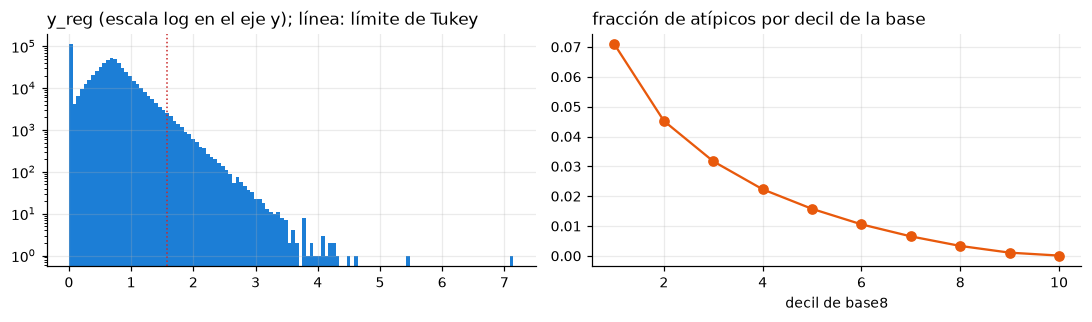

In [11]:
at = C.resumen_atipicos(tr, [C.OBJ, "ratio_t", "base8", "log_base8", "dist_km"])
print(at.round(3).to_string())
q1, q3 = tr[C.OBJ].quantile([0.25, 0.75])
lim = q3 + 1.5 * (q3 - q1)
es_at = tr[C.OBJ] > lim
print(f"límite superior de Tukey para y_reg: {lim:.3f} (razón {np.expm1(lim):.2f} veces la base); filas atípicas: {es_at.mean():.4f}")
dec_base = pd.qcut(tr["base8"], 10, labels=False)
print("fracción de atípicos por decil de base8 (1 = base más pequeña):",
      np.round(es_at.groupby(dec_base).mean().to_numpy(), 4))
print("fracción de atípicos según festivos en t+1:", es_at.groupby(tr["festivos_t1"].clip(upper=2)).mean().round(4).to_dict())
err = np.abs(tr[C.OBJ] - tr[C.OBJ].median())
top = err >= err.quantile(0.99)
imp = {"limite_tukey": float(lim), "frac_atipicos": float(es_at.mean()),
       "atipicos_por_decil_base8": es_at.groupby(dec_base).mean().tolist(),
       "frac_mae_top1": float(err[top].sum() / err.sum()), "frac_mse_top1": float((err[top] ** 2).sum() / (err ** 2).sum())}
print(f"el 1 % de filas con mayor error aporta {imp['frac_mae_top1']:.3f} del MAE y {imp['frac_mse_top1']:.3f} del MSE")
R["atipicos"] = imp | {"tabla": at.reset_index().to_dict("records")}

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(tr[C.OBJ], bins=120, color=C.AZUL)
ax[0].axvline(lim, color=C.ROJO, ls=":", lw=1)
ax[0].set_yscale("log")
ax[0].set_title("y_reg (escala log en el eje y); línea: límite de Tukey", loc="left")
ax[1].plot(range(1, 11), es_at.groupby(dec_base).mean().to_numpy(), "o-", color=C.NARANJA)
ax[1].set_xlabel("decil de base8")
ax[1].set_title("fracción de atípicos por decil de la base", loc="left")
plt.tight_layout()
C.figura(fig, "series_atipicos")
plt.show()

`y_reg` tiene asimetría de 0,549 y curtosis en exceso de 1,461, colas moderadas para una variable en
escala logarítmica. El límite superior de Tukey es 1,577 (3,84 veces la base) y deja fuera al 2,08 %
de las filas. Los atípicos se concentran en las bases pequeñas: son el 7,09 % del decil con menor
`base8` y el 0,01 % del decil con mayor base. Con pocos kilos de referencia, un envío normal
multiplica la razón. Los festivos no los explican: con 0, 1 y 2 festivos en t+1, la fracción de
atípicos es 2,05 %, 2,10 % y 2,57 %. Su peso en el error depende de la métrica: el 1 % de filas con
mayor error de la mediana constante aporta el 4,6 % del MAE y el 13,0 % del MSE.

* **Preprocesamiento.** No se eliminan ni se recortan. Son envíos reales y el modelo debe
  pronosticarlos. `log_base8` se mantiene como covariable para que el modelo sepa cuándo la razón es
  ruidosa.
* **Arquitectura.** El MAE como métrica primaria y una pérdida L1 o Huber evitan que este 2 % domine
  el ajuste, como pasaría con el MSE. El RMSE secundario mostrará su efecto.
* **Fuga.** Ninguna: el criterio de Tukey solo se usa para describir.

## B.7 Implicaciones para el diseño

| Hallazgo | Decisión | Dónde se aplica |
|---|---|---|
| Pronóstico de la semana siguiente | Horizonte h = 1, una salida directa (sin estrategia multi-paso) | `src/` (Lina) |
| ACF agrupada hasta el rezago 53; la ridge se estabiliza en 52 | Ventana L = 52 semanas, t−51 a t | `eda/decisiones_para_modelos.md` |
| 94,7 % de corredores estacionarios en `y_reg` | Sin diferenciar; escala de la ventana con `base8` de la fila | ventanas |
| Ausencias MNAR, el 72 % de ellas son ceros | Nivel 0 más máscaras `observado` e `iniciado`; sin interpolar | ventanas |
| 41,6 % de corredores con menos de 52 semanas; 6 % de varianza entre corredores | Modelo global; *embeddings* opcionales | modelos |
| ARCH y BDS rechazan; atípicos en bases pequeñas | MAE primaria; pérdida L1 o Huber | entrenamiento |
| Sin quiebres en la serie nacional | Validación de origen móvil con hueco de 8 semanas | `src/` (Lina) |

**Riesgo principal: fuga temporal.** Hay cuatro puntos que verificar en el código de los modelos:
(1) la ventana termina en t y nunca toma la columna t+1 de la matriz; (2) los escaladores y
cualquier estadístico de normalización se ajustan solo con las filas de ajuste de cada origen;
(3) entre el ajuste y la evaluación de cada origen queda el hueco de 8 semanas, porque `base8` y
las variables de 26 semanas comparten semanas con las filas vecinas; (4) la parada temprana usa un
bloque posterior al ajuste, no la prueba.

In [12]:
ruta = C.guardar("series_resultados", R)
print("resultados guardados en", ruta.relative_to(C.RAIZ))

resultados guardados en eda/resultados/series_resultados.json
